In [1]:
# [2026-04-28] After the MediaWiki API rewrite below, only pandas, matplotlib,
# and (transitively) `requests` are needed. The selenium / webdriver_manager /
# logging / time imports are kept here only so the legacy cells still parse
# if you re-enable them. Safe to delete once the API path is confirmed working.
import pandas as pd
import time
from selenium import webdriver
from webdriver_manager.chrome import ChromeDriverManager
from selenium.webdriver.common.by import By
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.chrome.options import Options
import matplotlib.pyplot as plt
import os
import logging


# Full code

In [2]:
# ============================================================
# [BEGIN: 2026-04-28 — Cloudflare workaround, MediaWiki API rewrite]
# Replaces the prior Selenium scraper that breakingbad.fandom.com
# blocks via Cloudflare. Uses the public MediaWiki API instead.
# ============================================================
import re
import requests

API_URL = "https://breakingbad.fandom.com/api.php"
PARENT_CATEGORY = "Category:Breaking_Bad_Characters"
HEADERS = {"User-Agent": "network-of-breaking-bad/0.1 (educational; contact: local)"}


def api_categorymembers(category_title, cmtype=None, limit=500):
    """Fetch all members of a Fandom category via the MediaWiki API,
    handling cmcontinue pagination. Returns a list of {pageid, ns, title}."""
    members = []
    params = {
        "action": "query",
        "list": "categorymembers",
        "cmtitle": category_title,
        "cmlimit": limit,
        "format": "json",
    }
    if cmtype:
        params["cmtype"] = cmtype
    while True:
        r = requests.get(API_URL, params=params, headers=HEADERS, timeout=30)
        r.raise_for_status()
        data = r.json()
        members.extend(data.get("query", {}).get("categorymembers", []))
        cont = data.get("continue", {}).get("cmcontinue")
        if not cont:
            break
        params["cmcontinue"] = cont
    return members


# Discover season subcategories under the parent characters category.
subcats = api_categorymembers(PARENT_CATEGORY, cmtype="subcat")
season_re = re.compile(r"Season \d+[AB]?")
seasons = []
for sc in subcats:
    title = sc["title"]  # e.g. "Category:Season 1 Characters (Breaking Bad)"
    if season_re.search(title):
        seasons.append({"season_name": title, "category_title": title})
# ============================================================
# [END: 2026-04-28 — MediaWiki API rewrite]
# ============================================================


In [3]:
seasons

[{'season_name': 'Category:Season 1 Characters (Breaking Bad)',
  'category_title': 'Category:Season 1 Characters (Breaking Bad)'},
 {'season_name': 'Category:Season 2 Characters (Breaking Bad)',
  'category_title': 'Category:Season 2 Characters (Breaking Bad)'},
 {'season_name': 'Category:Season 3 Characters (Breaking Bad)',
  'category_title': 'Category:Season 3 Characters (Breaking Bad)'},
 {'season_name': 'Category:Season 4 Characters (Breaking Bad)',
  'category_title': 'Category:Season 4 Characters (Breaking Bad)'},
 {'season_name': 'Category:Season 5A Characters (Breaking Bad)',
  'category_title': 'Category:Season 5A Characters (Breaking Bad)'},
 {'season_name': 'Category:Season 5B Characters (Breaking Bad)',
  'category_title': 'Category:Season 5B Characters (Breaking Bad)'}]

In [4]:
# ============================================================
# [BEGIN: 2026-04-28 — Cloudflare workaround, MediaWiki API rewrite]
# Replaces the prior Selenium scraper that breakingbad.fandom.com
# blocks via Cloudflare. Uses the public MediaWiki API instead.
# ============================================================
character_list = []

for season in seasons:
    # Pull only article pages (cmtype=page) — skips nested subcategories.
    members = api_categorymembers(season["category_title"], cmtype="page")

    # Normalise "Category:Season 5A Characters (Breaking Bad)" -> "Season 5"
    # to match the original notebook's output schema.
    match = season_re.search(season["season_name"])
    raw = match.group(0) if match else season["season_name"]
    clean_season_name = re.sub(r"[AB]$", "", raw)

    for m in members:
        character_list.append({"season": clean_season_name, "character": m["title"]})
# ============================================================
# [END: 2026-04-28 — MediaWiki API rewrite]
# ============================================================


In [5]:
pd.DataFrame(character_list)

,season,character
0,Season 1,List of bit parts in Breaking Bad/Season 1
1,Season 1,Hugo Archilleya
2,Season 1,Badger
3,Season 1,Dr. Belknap
4,Season 1,Ben
...,...,...
374,Season 5,Jack Welker
375,Season 5,Holly White
376,Season 5,Skyler White
377,Season 5,Walter White


## Number of characters per season

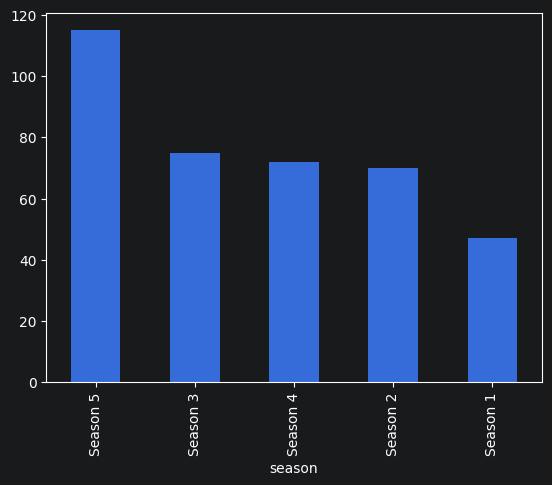

In [6]:
character_df = pd.DataFrame(character_list)

character_df['season'].value_counts().plot(kind="bar")
plt.show()

In [7]:
# ============================================================
# [BEGIN: 2026-04-28 — Cloudflare workaround, MediaWiki API rewrite]
# Replaces the prior Selenium scraper that breakingbad.fandom.com
# blocks via Cloudflare. Uses the public MediaWiki API instead.
# ============================================================
# Persist the character list so extracting_relationships.ipynb can read it.
# The relationship notebook expects a `character` column at minimum.
character_df = pd.DataFrame(character_list).drop_duplicates(subset=["character"]).reset_index(drop=True)
character_df.to_csv("characters_bd.csv", index=False)
print(f"Wrote characters_bd.csv with {len(character_df)} rows.")
# ============================================================
# [END: 2026-04-28 — MediaWiki API rewrite]
# ============================================================


Wrote characters_bd.csv with 228 rows.
